# Lab 7 — Đánh giá mô hình

Nguyễn Đình Huy — MSSV: 2474802010140

Mỗi mục/bài có đúng một cell code. Giữ hai CSV trong `data/`, chạy từ thư mục Lab hoặc `code/`. Trên Colab có thể tải hai CSV vào thư mục hiện tại. Hình lưu ở `figures/`; chạy `scripts/run_all.py` để cập nhật notebook và xuất nhật ký ở `outputs/`.

## Mục 2 — Khi accuracy đánh lừa (h1_do_bua.py)

Kich thuoc bang: (1200, 5)
   diem_tb  so_buoi_vang  tin_chi_no  gio_lam_them  bo_hoc
0      8.0             3           0             0       0
1      8.9             5           1             7       0
2      3.3             3           1             4       0
3      6.4             3           0             7       0
4      7.9             3           5            23       0

So sinh vien moi lop:
bo_hoc
0    1081
1     119
Ty le bo hoc: 0.099

Tap kiem tra: 300 ban, 30 ban bo hoc

Mo hinh luoi      accuracy 0.9000, tim ra 0 tren 30 ban bo hoc
Hoi quy logistic  accuracy 0.9467, tim ra 17 tren 30 ban bo hoc


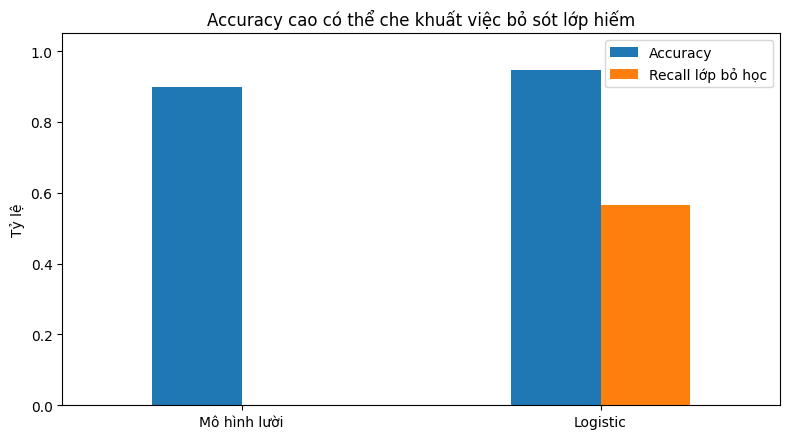

In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("So sinh vien moi lop:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Ty le bo hoc: {df['bo_hoc'].mean():.3f}")
print()
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
# Giữ tỷ lệ bỏ học ở cả tập học và tập kiểm tra.
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print(f"Tap kiem tra: {len(y_te)} ban, {y_te.sum()} ban bo hoc")
print()
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)
lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)
ket_qua = []
for ten, du in [("Mo hinh luoi", du_luoi), ("Hoi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:17s} accuracy {acc:.4f}, tim ra {tim_ra} tren {y_te.sum()} ban bo hoc")
    ket_qua.append([acc, tim_ra / y_te.sum()])

# Minh họa vì sao accuracy cao chưa đủ trên bộ dữ liệu lệch lớp.
pd.DataFrame(ket_qua, index=["Mô hình lười", "Logistic"], columns=["Accuracy", "Recall lớp bỏ học"]).plot.bar(rot=0, figsize=(8, 4.5))
plt.ylabel("Tỷ lệ")
plt.ylim(0, 1.05)
plt.title("Accuracy cao có thể che khuất việc bỏ sót lớp hiếm")

plt.tight_layout()
plt.savefig(thu_muc_hinh / "accuracy_va_recall.png", dpi=150)
plt.show()
plt.close()


## Mục 3 — Ma trận nhầm lẫn (h2_ma_tran.py)

Tu dem:
  TP = 17 (doan bo hoc, dung la bo hoc)
  FP = 3 (bao dong nham)
  FN = 13 (bo sot)
  TN = 267 (doan khong bo, dung la khong bo)
  Tong = 300

confusion_matrix cua scikit-learn:
[[267   3]
 [ 13  17]]
Thu tu khi trai ra: TN, FP, FN, TP = [267   3  13  17]

Accuracy tinh tu bon o: (17 + 267) / 300 = 0.9467
So ban bi bao co nguy co: TP + FP = 20


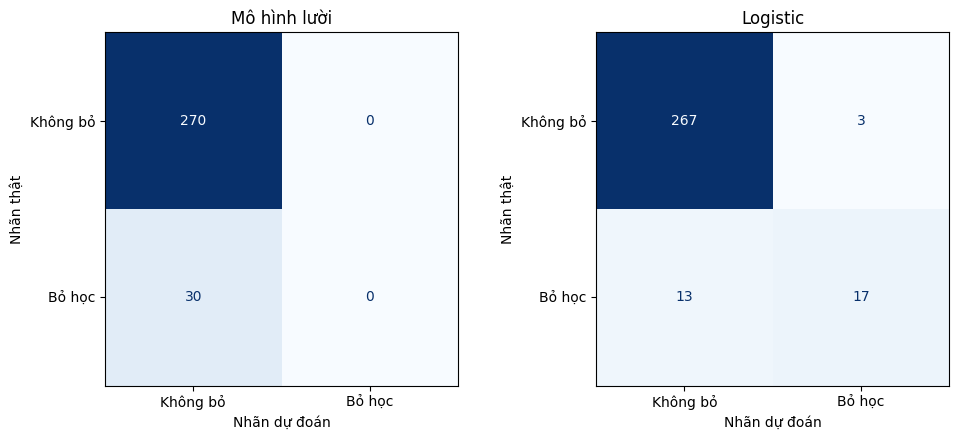

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
lr = make_pipeline(StandardScaler(), LogisticRegression())

du = lr.fit(X_tr, y_tr).predict(X_te)
that = y_te.to_numpy()
# Mỗi ô ứng với một cặp nhãn thật và nhãn đoán.
tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))
print("Tu dem:")
print(f"  TP = {tp} (doan bo hoc, dung la bo hoc)")
print(f"  FP = {fp} (bao dong nham)")
print(f"  FN = {fn} (bo sot)")
print(f"  TN = {tn} (doan khong bo, dung la khong bo)")
print(f"  Tong = {tp + fp + fn + tn}")
print()
m = confusion_matrix(that, du)
print("confusion_matrix cua scikit-learn:")
print(m)
print("Thu tu khi trai ra: TN, FP, FN, TP =", m.ravel())
print()
acc = (tp + tn) / (tp + fp + fn + tn)
print(f"Accuracy tinh tu bon o: ({tp} + {tn}) / {len(that)} = {acc:.4f}")
print(f"So ban bi bao co nguy co: TP + FP = {tp + fp}")

du_luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr).predict(X_te)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, nhan, ten in [(axes[0], du_luoi, "Mô hình lười"), (axes[1], du, "Logistic")]:
    ConfusionMatrixDisplay(confusion_matrix(y_te, nhan), display_labels=["Không bỏ", "Bỏ học"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set(title=ten, xlabel="Nhãn dự đoán", ylabel="Nhãn thật")

plt.tight_layout()
plt.savefig(thu_muc_hinh / "ma_tran_nham_lan.png", dpi=150)
plt.show()
plt.close()


## Mục 4 — Precision, recall và F1 (h3_precision_recall.py)

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
lr = make_pipeline(StandardScaler(), LogisticRegression())

du = lr.fit(X_tr, y_tr).predict(X_te)
tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()
p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)
print("Tinh tay tu bon o:")
print(f"  Precision = {tp} / ({tp} + {fp}) = {p:.4f}")
print(f"  Recall    = {tp} / ({tp} + {fn}) = {r:.4f}")
print(f"  F1        = 2 x {p:.4f} x {r:.4f} / ({p:.4f} + {r:.4f}) = {f1:.4f}")
print()
print("Tinh bang scikit-learn:")
print(f"  Precision = {precision_score(y_te, du):.4f}")
print(f"  Recall    = {recall_score(y_te, du):.4f}")
print(f"  F1        = {f1_score(y_te, du):.4f}")
print()
print("Bao cao day du:")
print(classification_report(y_te, du, digits=4, target_names=["khong bo", "bo hoc"]))


Tinh tay tu bon o:
  Precision = 17 / (17 + 3) = 0.8500
  Recall    = 17 / (17 + 13) = 0.5667
  F1        = 2 x 0.8500 x 0.5667 / (0.8500 + 0.5667) = 0.6800

Tinh bang scikit-learn:
  Precision = 0.8500
  Recall    = 0.5667
  F1        = 0.6800

Bao cao day du:
              precision    recall  f1-score   support

    khong bo     0.9536    0.9889    0.9709       270
      bo hoc     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



## Mục 5 — Đổi và chọn ngưỡng đúng cách (h4_nguong.py)

Tap kiem tra, doi nguong
nguong so bao  TP  FP  FN  precision  recall   F1
 0.5     20   17   3  13   0.8500  0.5667  0.6800
 0.4     21   18   3  12   0.8571  0.6000  0.7059
 0.3     29   21   8   9   0.7241  0.7000  0.7119
 0.2     42   24  18   6   0.5714  0.8000  0.6667
 0.1     61   26  35   4   0.4262  0.8667  0.5714



Nguong cho F1 cao nhat tren tap hoc: 0.25 (F1 kiem dinh cheo 0.6473)
Tap kiem tra voi nguong 0.25: precision 0.6571, recall 0.7667, F1 0.7077


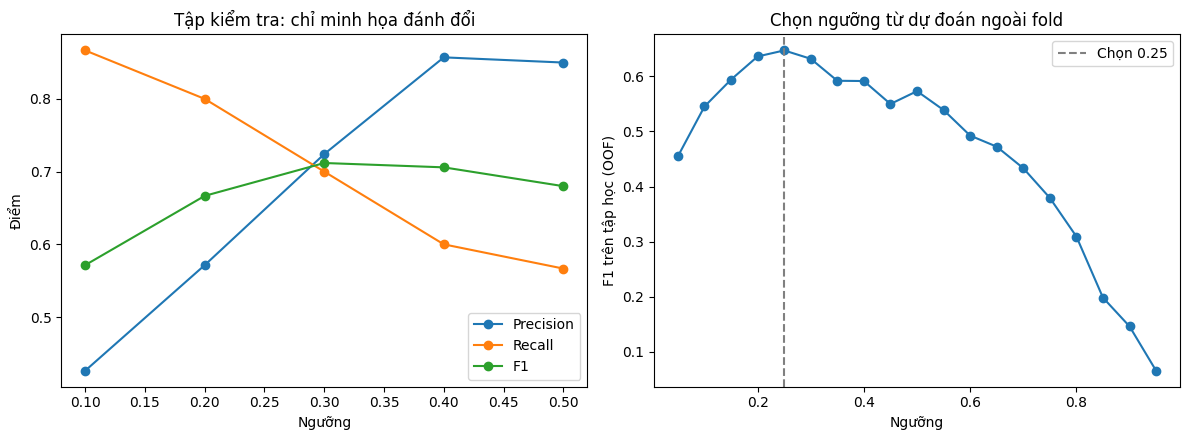

In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict
df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
lr = make_pipeline(StandardScaler(), LogisticRegression())

lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]
print("Tap kiem tra, doi nguong")
print("nguong so bao  TP  FP  FN  precision  recall   F1")
bang_nguong = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du = (xs >= t).astype(int)
    tp = int(((du == 1) & (y_te == 1)).sum())
    fp = int(((du == 1) & (y_te == 0)).sum())
    fn = int(((du == 0) & (y_te == 1)).sum())
    print(f" {t:.1f}   {du.sum():4d}  {tp:3d} {fp:3d} {fn:3d}"
          f"   {precision_score(y_te, du):.4f}  {recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")
    bang_nguong.append([t, precision_score(y_te, du), recall_score(y_te, du), f1_score(y_te, du)])
print()
# Bảng trên để minh họa; không dùng nó để chọn ngưỡng.
# Mỗi mẫu học nhận xác suất từ mô hình chưa từng học mẫu đó.
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Nguong cho F1 cao nhat tren tap hoc: {t_tot} (F1 kiem dinh cheo {max(f1_hoc):.4f})")
du = (xs >= t_tot).astype(int)
print(f"Tap kiem tra voi nguong {t_tot}: precision {precision_score(y_te, du):.4f}, "
      f"recall {recall_score(y_te, du):.4f}, F1 {f1_score(y_te, du):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bang_ve = pd.DataFrame(bang_nguong, columns=["Ngưỡng", "Precision", "Recall", "F1"]).sort_values("Ngưỡng")
bang_ve.plot(x="Ngưỡng", ax=axes[0], marker="o")
axes[0].set(title="Tập kiểm tra: chỉ minh họa đánh đổi", ylabel="Điểm")
axes[1].plot(cac_nguong, f1_hoc, "o-")
axes[1].axvline(t_tot, color="gray", linestyle="--", label=f"Chọn {t_tot:.2f}")
axes[1].set(title="Chọn ngưỡng từ dự đoán ngoài fold", xlabel="Ngưỡng", ylabel="F1 trên tập học (OOF)")
axes[1].legend()

plt.tight_layout()
plt.savefig(thu_muc_hinh / "chon_nguong.png", dpi=150)
plt.show()
plt.close()


## Mục 6 — ROC, AUC và so mô hình (h5_roc_auc.py)

Duong ROC co 28 diem. Vai diem dau:
  bao dong nham  recall
     0.0000     0.0000
     0.0000     0.0333
     0.0000     0.4000
     0.0074     0.4000
     0.0074     0.5333
     0.0111     0.5333
AUC cua logistic = 0.9449

Mo hinh         AUC     recall   F1  (nguong 0.5)
 Logistic       0.9449  0.5667  0.6800
 Naive Bayes    0.9336  0.3667  0.5116
 KNN, k = 15    0.9274  0.2333  0.3684
 Cay sau 4      0.8803  0.4667  0.5957


 Rung 200 cay   0.9249  0.5667  0.6538
 SVM RBF        0.8996  0.5000  0.6250


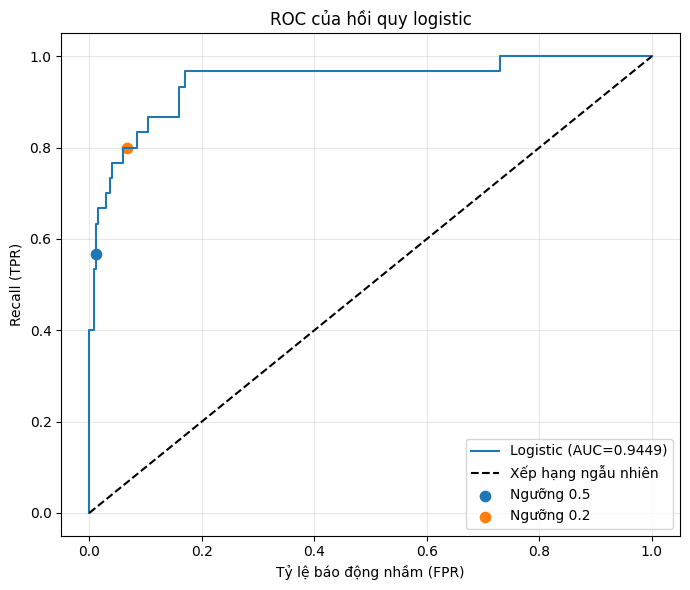

In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score, roc_auc_score, roc_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
lr = make_pipeline(StandardScaler(), LogisticRegression())

xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print("  bao dong nham  recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"     {a:.4f}     {b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}")
print()
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(), SVC(probability=True, random_state=0)),
}
print("Mo hinh         AUC     recall   F1  (nguong 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du = (p >= 0.5).astype(int)
    print(f" {ten:14s} {roc_auc_score(y_te, p):.4f}  {recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Logistic (AUC={roc_auc_score(y_te, xs):.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Xếp hạng ngẫu nhiên")
for t in [0.5, 0.2]:
    du = xs >= t
    ty_le_bao_nham = np.sum(du & (y_te == 0)) / np.sum(y_te == 0)
    ty_le_tim_ra = np.sum(du & (y_te == 1)) / np.sum(y_te == 1)
    plt.scatter(ty_le_bao_nham, ty_le_tim_ra, s=55, label=f"Ngưỡng {t}")
plt.xlabel("Tỷ lệ báo động nhầm (FPR)")
plt.ylabel("Recall (TPR)")
plt.title("ROC của hồi quy logistic")
plt.legend(loc="lower right")
plt.grid(alpha=.3)

plt.tight_layout()
plt.savefig(thu_muc_hinh / "roc_logistic.png", dpi=150)
plt.show()
plt.close()


## Mục 7 — Kiểm định chéo và cân bằng lớp (h6_can_bang.py)

Khong stratify, so ban bo hoc trong tap kiem tra:
  [22, 26, 35, 29, 32, 27, 28, 20, 27, 23]

Kiem dinh cheo 5 phan tren tap hoc:
 accuracy   0.9289
 precision  0.7044


 recall     0.4810
 f1         0.5652

Tap kiem tra  precision recall   F1
 Binh thuong   0.8500   0.5667 0.6800
 Can bang lop  0.4483   0.8667 0.5909


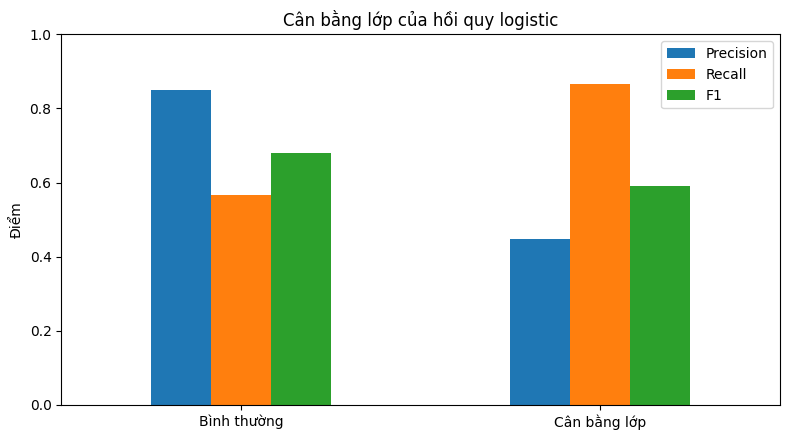

In [6]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score
df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

print("Khong stratify, so ban bo hoc trong tap kiem tra:")
dem = []
for rs in range(10):
    _, _, _, y_te_thu = train_test_split(X, y, test_size=0.25, random_state=rs)
    dem.append(int(y_te_thu.sum()))
print(" ", dem)
print()
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
lr = make_pipeline(StandardScaler(), LogisticRegression())

print("Kiem dinh cheo 5 phan tren tap hoc:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    d = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm)
    print(f" {tm:10s} {d.mean():.4f}")
print()
cb = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
print("Tap kiem tra  precision recall   F1")
ket_qua = []
for ten, mh in [("Binh thuong", lr), ("Can bang lop", cb)]:
    du = mh.fit(X_tr, y_tr).predict(X_te)
    print(f" {ten:12s}  {precision_score(y_te, du):.4f}   {recall_score(y_te, du):.4f} {f1_score(y_te, du):.4f}")
    ket_qua.append([precision_score(y_te, du), recall_score(y_te, du), f1_score(y_te, du)])
pd.DataFrame(ket_qua, index=["Bình thường", "Cân bằng lớp"], columns=["Precision", "Recall", "F1"]).plot.bar(rot=0, figsize=(8, 4.5))
plt.ylabel("Điểm")
plt.title("Cân bằng lớp của hồi quy logistic")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(thu_muc_hinh / "can_bang_logistic.png", dpi=150)
plt.show()
plt.close()
